# Lecture 17: every figure in the slides

These cells are the code that produced the autoencoders vaes vqvae figures in the deck, with each file write replaced by an inline plot. The notebook runs independently of the slide repository.

In [1]:
# Colab opens this notebook on its own, so fetch the data files that sit
# beside it in the course repository. Running locally, this does nothing.
from pathlib import Path as _Path
import urllib.request as _req
_RAW = 'https://raw.githubusercontent.com/ZhuoranYang/sds265-fall26/main/demos/17-autoencoders-vaes-vqvae/'
for _name in ['SklearnDigits.csv']:
    if not _Path(_name).exists():
        _req.urlretrieve(_RAW + _name, _name)

In [2]:
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The course palette and figure sizes, copied from slides/figures/sds265_style.py
BLUE, BLUE_BRIGHT, RED, GREEN = '#00356B', '#286DC0', '#7A3E47', '#5B7864'
INK, MUTED, RULE, BLUE_PALE = '#202A35', '#66727E', '#D8E0E8', '#F2F6FA'
BLUE_FILL, RED_FILL, GREEN_FILL = '#8C9FB1', '#B0846F', '#9AAE96'
MORANDI_BLUE, MORANDI_CLAY, MORANDI_SAGE = '#8C9FB1', '#B0846F', '#9AAE96'
MORANDI_MAUVE, MORANDI_SAND, MORANDI_STONE = '#A98FA0', '#C7B392', '#8A8F8A'
MORANDI = [MORANDI_BLUE, MORANDI_CLAY, MORANDI_SAGE, MORANDI_MAUVE, MORANDI_SAND, MORANDI_STONE]
MORANDI_EDGE = {MORANDI_BLUE: '#5C7186', MORANDI_CLAY: '#835747', MORANDI_SAGE: '#6B8067',
                MORANDI_MAUVE: '#7C6373', MORANDI_SAND: '#9A8763', MORANDI_STONE: '#5F645F'}
CYCLE = MORANDI
TEXTWIDTH, TEXTHEIGHT = 5.63, 3.09
FULL, FULL_TALL, FULL_SHORT = (TEXTWIDTH, 2.0), (TEXTWIDTH, 2.35), (TEXTWIDTH, 1.7)
HALF, HALF_TALL = (2.70, 2.05), (2.70, 2.45)

def use_course_style():
    mpl.rcParams.update({'figure.dpi': 130, 'font.size': 9, 'axes.titlecolor': BLUE,
                         'axes.edgecolor': MUTED, 'axes.linewidth': .7,
                         'axes.spines.top': False, 'axes.spines.right': False,
                         'xtick.color': MUTED, 'ytick.color': MUTED,
                         'legend.frameon': False, 'lines.linewidth': 1.8,
                         'axes.prop_cycle': mpl.cycler(color=CYCLE)})

def save(fig, *paths):     # the deck writes files; the notebook shows the plot
    plt.show()
    return Path(paths[0]) if paths else Path('figure.pdf')

use_course_style()
# The deck scripts derive output paths from OUT and NOTES. Nothing is written
# here, so both point at the working directory and the notebook runs anywhere.
OUT = Path('.')
NOTES = Path('.')

### `make_latent_figures.py`

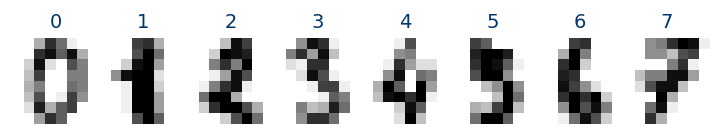

In [3]:
from __future__ import annotations


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Ellipse



SEED = 26520
COLORS = np.array([BLUE, RED, GREEN, "#8C6D9E", "#C28E4B", "#4D8D9A"])
rng = np.random.default_rng(SEED)

digits = pd.read_csv(Path("SklearnDigits.csv"))
X_digits = digits.drop(columns="target").to_numpy(float) / 16
y_digits = digits["target"].to_numpy(int)


def digits_data() -> None:
    indices = [np.flatnonzero(y_digits == label)[0] for label in range(8)]
    fig, axes = plt.subplots(1, 8, figsize=FULL_SHORT)
    for ax, index in zip(axes, indices):
        ax.imshow(X_digits[index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(str(y_digits[index])); ax.axis("off")
    fig.tight_layout(w_pad=.08)
    save(fig, OUT / "digits-data.pdf", OUT / "digits-data.svg")


# UNUSED: no deck includes digits-pca-reconstruction.pdf. Kept in case a slide wants it back.
def digits_pca() -> None:
    centered = X_digits - X_digits.mean(axis=0)
    _, _, vt = np.linalg.svd(centered, full_matrices=False)
    rank = 8
    reconstructed = (centered @ vt[:rank].T) @ vt[:rank] + X_digits.mean(axis=0)
    indices = [np.flatnonzero(y_digits == label)[1] for label in range(6)]
    fig, axes = plt.subplots(2, 6, figsize=FULL_TALL)
    for column, index in enumerate(indices):
        axes[0, column].imshow(X_digits[index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
        axes[1, column].imshow(reconstructed[index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
        axes[0, column].axis("off"); axes[1, column].axis("off")
    axes[0, 0].set_ylabel("original"); axes[1, 0].set_ylabel("rank 8")
    fig.tight_layout(w_pad=.08, h_pad=.10)
    save(fig, OUT / "digits-pca-reconstruction.pdf", OUT / "digits-pca-reconstruction.svg")


# UNUSED: no deck includes linear-vs-nonlinear.pdf. Kept in case a slide wants it back.
def nonlinear_manifold() -> None:
    t = np.linspace(-2.4, 2.4, 220)
    x = np.c_[t, .58 * t ** 2 + .13 * rng.normal(size=len(t))]
    centered = x - x.mean(0)
    vector = np.linalg.svd(centered, full_matrices=False)[2][0]
    projected = np.outer(centered @ vector, vector) + x.mean(0)
    fig, axes = plt.subplots(1, 3, figsize=FULL_TALL)
    axes[0].scatter(x[:, 0], x[:, 1], c=t, cmap="RdBu_r", s=7); axes[0].set_title("Curved data")
    axes[1].scatter(x[:, 0], x[:, 1], color=MUTED, s=6, alpha=.30)
    order = np.argsort(projected[:, 0]); axes[1].plot(projected[order, 0], projected[order, 1], color=MORANDI_EDGE[MORANDI_BLUE])
    axes[1].set_title("Linear subspace")
    axes[2].scatter(t, np.zeros_like(t), c=t, cmap="RdBu_r", s=8); axes[2].set_title("Nonlinear code")
    for ax in axes: ax.set_xticks([]); ax.set_yticks([])
    save(fig, OUT / "linear-vs-nonlinear.pdf", OUT / "linear-vs-nonlinear.svg")


def pca_ppca() -> None:
    """Build the model in three steps: signal on a line, plus noise, then the fitted direction."""
    direction = np.array([.85, .53]); direction = direction / np.linalg.norm(direction)
    loading = 1.7 * direction[:, None]                    # W, a 2-by-1 matrix
    noise_sd = .32
    z = rng.normal(size=260)
    signal = z[:, None] * loading[:, 0][None, :]          # Wz
    x = signal + rng.normal(scale=noise_sd, size=(260, 2))

    span = 3.1
    line = np.array([[-span, span]]) * direction[:, None]
    covariance = loading @ loading.T + noise_sd ** 2 * np.eye(2)
    values, vectors = np.linalg.eigh(covariance)
    order = values.argsort()[::-1]
    values, vectors = values[order], vectors[:, order]

    centered = x - x.mean(axis=0)
    first_pc = np.linalg.svd(centered, full_matrices=False)[2][0]
    if first_pc @ direction < 0:
        first_pc = -first_pc
    degrees = np.degrees(np.arccos(np.clip(abs(first_pc @ direction), 0, 1)))

    fig, axes = plt.subplots(1, 3, figsize=FULL_TALL)
    axes[0].plot(line[0], line[1], color=MUTED, lw=.8, zorder=1)
    axes[0].scatter(signal[:, 0], signal[:, 1], s=7, color=MORANDI_SAGE, alpha=.55, zorder=2)
    axes[0].set_title("$Wz$ alone: a line")

    axes[1].plot(line[0], line[1], color=MUTED, lw=.8, zorder=1)
    axes[1].scatter(x[:, 0], x[:, 1], s=7, color=MORANDI_BLUE, alpha=.45, zorder=2)
    axes[1].set_title("$x=Wz+\\epsilon$: a cloud")

    axes[2].scatter(x[:, 0], x[:, 1], s=7, color=MORANDI_BLUE, alpha=.32, zorder=1)
    for scaling in (1, 2):
        axes[2].add_patch(Ellipse((0, 0), 2 * scaling * np.sqrt(values[0]), 2 * scaling * np.sqrt(values[1]),
                                  angle=np.degrees(np.arctan2(vectors[1, 0], vectors[0, 0])),
                                  fill=False, color=MORANDI_CLAY, lw=1.2, zorder=2))
    axes[2].plot(line[0], line[1], color=MUTED, lw=.8, zorder=3)
    axes[2].plot([-span * first_pc[0], span * first_pc[0]], [-span * first_pc[1], span * first_pc[1]],
                 color=INK, ls=(0, (4, 3)), lw=1.3, zorder=4)
    axes[2].set_title("first PC on $\\mathrm{col}(W)$")

    for ax in axes:
        ax.set_aspect("equal", adjustable="datalim")
        ax.set_xticks([]); ax.set_yticks([])
    fig.tight_layout(w_pad=.5)
    save(fig, OUT / "pca-ppca-bridge.pdf", OUT / "pca-ppca-bridge.svg")
    print(f"angle between first PC and col(W): {degrees:.2f} degrees")


# UNUSED: no deck includes latent-holes.pdf. Kept in case a slide wants it back.
def latent_holes() -> None:
    a = rng.normal([-1.4, .6], [.28, .35], (100, 2)); b = rng.normal([1.25, .75], [.32, .22], (100, 2))
    c = rng.normal([.2, -1.25], [.22, .32], (100, 2)); codes = np.r_[a, b, c]
    prior = rng.normal(size=(300, 2))
    fig, axes = plt.subplots(1, 2, figsize=FULL_SHORT)
    axes[0].scatter(codes[:, 0], codes[:, 1], c=np.repeat(COLORS[:3], 100), s=8, alpha=.65)
    axes[0].scatter([0], [0], marker="x", s=45, color=INK); axes[0].set_title("Encoded islands and a hole")
    axes[1].scatter(prior[:, 0], prior[:, 1], color=MORANDI_SAGE, s=7, alpha=.45); axes[1].set_title("Chosen Gaussian prior")
    for ax in axes: ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    save(fig, OUT / "latent-holes.pdf", OUT / "latent-holes.svg")


# UNUSED: no deck includes reconstruction-kl-tradeoff.pdf. Kept in case a slide wants it back.
def beta_tradeoff() -> None:
    beta = np.logspace(-2, 1, 80)
    reconstruction = .07 + .15 * np.log1p(3 * beta)
    kl = 1.35 / (1 + 1.8 * beta) + .04
    fig, ax = plt.subplots(figsize=FULL_SHORT); second = ax.twinx()
    first_lines = ax.plot(beta, reconstruction, color=MORANDI_EDGE[MORANDI_CLAY], label="reconstruction error")
    second_lines = second.plot(beta, kl, color=MORANDI_EDGE[MORANDI_SAGE], label="latent KL")
    ax.set(xscale="log", xlabel="KL weight beta", ylabel="Reconstruction error")
    second.set_ylabel("KL to prior")
    ax.legend(first_lines + second_lines, [line.get_label() for line in first_lines + second_lines], loc="center left")
    save(fig, OUT / "reconstruction-kl-tradeoff.pdf", OUT / "reconstruction-kl-tradeoff.svg")


def posterior_collapse() -> None:
    labels = np.repeat(np.arange(3), 100)
    active = np.r_[rng.normal([-1.4, 0], [.25, .4], (100, 2)), rng.normal([0, 1.1], [.3, .25], (100, 2)),
                   rng.normal([1.4, 0], [.25, .4], (100, 2))]
    collapsed = rng.normal(scale=.42, size=(300, 2))
    fig, axes = plt.subplots(1, 2, figsize=FULL_SHORT)
    for ax, z, title in zip(axes, [active, collapsed], ["Posterior depends on x", "Every posterior resembles prior"]):
        ax.scatter(z[:, 0], z[:, 1], c=COLORS[labels], s=7, alpha=.6)
        ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal", adjustable="datalim")
    save(fig, OUT / "posterior-collapse.pdf", OUT / "posterior-collapse.svg")


def vq_codebook() -> None:
    codebook = np.array([[-1.4, -.8], [-1.1, 1.1], [.1, .1], [1.1, 1.2], [1.45, -.7]])
    grid_x, grid_y = np.meshgrid(np.linspace(-2.3, 2.3, 240), np.linspace(-1.8, 1.8, 190))
    grid = np.c_[grid_x.ravel(), grid_y.ravel()]
    regions = ((grid[:, None, :] - codebook[None, :, :]) ** 2).sum(2).argmin(1).reshape(grid_x.shape)
    points = np.vstack([rng.normal(code, [.35, .32], (45, 2)) for code in codebook])
    labels = ((points[:, None, :] - codebook[None, :, :]) ** 2).sum(2).argmin(1)
    fig, ax = plt.subplots(figsize=FULL_SHORT)
    ax.contourf(grid_x, grid_y, regions, levels=np.arange(6) - .5, colors=COLORS[:5], alpha=.12)
    ax.scatter(points[:, 0], points[:, 1], c=COLORS[labels], s=8, alpha=.5)
    ax.scatter(codebook[:, 0], codebook[:, 1], marker="D", c=COLORS[:5], s=48, edgecolors=INK, linewidths=.6)
    ax.set(xticks=[], yticks=[])
    save(fig, OUT / "vq-codebook.pdf", OUT / "vq-codebook.svg")


# UNUSED: no deck includes codebook-usage.pdf. Kept in case a slide wants it back.
def code_usage() -> None:
    usage = np.array([310, 255, 160, 95, 62, 28, 8, 2, 0, 0, 0, 0])
    probabilities = usage / usage.sum()
    perplexity = np.exp(-(probabilities[probabilities > 0] * np.log(probabilities[probabilities > 0])).sum())
    fig, ax = plt.subplots(figsize=FULL_SHORT)
    ax.bar(np.arange(len(usage)), usage, color=[BLUE if value else "#D8E0E8" for value in usage])
    ax.set(xlabel="Codebook index", ylabel="Assignments", title=f"12 available codes; 8 active; perplexity {perplexity:.1f}")
    save(fig, OUT / "codebook-usage.pdf", OUT / "codebook-usage.svg")


def variational_gap() -> None:
    """A curved posterior and the closest diagonal Gaussian: the gap VI accepts."""
    from scipy.optimize import minimize

    def log_target(z1, z2):
        """Unnormalized log posterior: a banana, as a stand-in for a nonlinear decoder."""
        return -.5 * z1 ** 2 - .5 * (z2 - .6 * (z1 ** 2 - 2)) ** 2

    grid = np.linspace(-3.4, 3.4, 260)
    mesh1, mesh2 = np.meshgrid(grid, grid)
    density = np.exp(log_target(mesh1, mesh2))

    draws = np.random.default_rng(SEED).normal(size=(4000, 2))

    def reverse_kl(parameters):
        mean, log_scale = parameters[:2], parameters[2:]
        sample = mean + np.exp(log_scale) * draws
        entropy = log_scale.sum()
        return -(entropy + log_target(sample[:, 0], sample[:, 1]).mean())

    fit = minimize(reverse_kl, np.array([0., 0., 0., 0.]), method="Nelder-Mead",
                   options={"xatol": 1e-4, "fatol": 1e-4, "maxiter": 4000})
    mean, scale = fit.x[:2], np.exp(fit.x[2:])

    fig, ax = plt.subplots(figsize=FULL_TALL)
    ax.contour(mesh1, mesh2, density, levels=7, colors=[MUTED], linewidths=.8)
    ax.contour(mesh1, mesh2, density, levels=[density.max() * .32], colors=[INK], linewidths=1.4)
    for scaling in (1, 2):
        ax.add_patch(Ellipse(mean, 2 * scaling * scale[0], 2 * scaling * scale[1],
                             fill=False, color=MORANDI_CLAY, lw=1.4))
    ax.scatter(*mean, color=MORANDI_CLAY, s=18, zorder=4)
    ax.annotate("true posterior $p_\\theta(z\\mid x)$", (.02, .95), xycoords="axes fraction",
                va="top", color=INK, fontsize=8.5)
    ax.annotate("best diagonal Gaussian $q$", (.98, .95), xycoords="axes fraction",
                ha="right", va="top", color=RED, fontsize=8.5)
    ax.set(xlabel="$z_1$", ylabel="$z_2$", xticks=[], yticks=[],
           xlim=(-3.4, 3.4), ylim=(-2.8, 3.4))
    save(fig, OUT / "variational-gap.pdf", OUT / "variational-gap.svg")




# Calls preserved from the script's __main__ block.
digits_data()

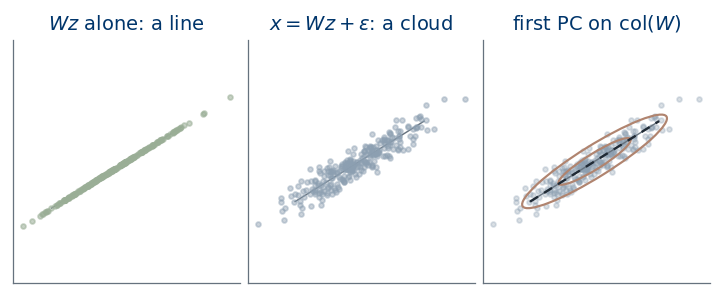

angle between first PC and col(W): 0.02 degrees


In [4]:
pca_ppca()

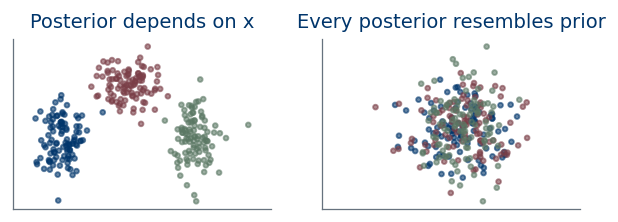

In [5]:
posterior_collapse()

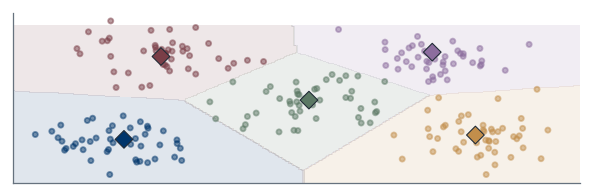

In [6]:
vq_codebook()

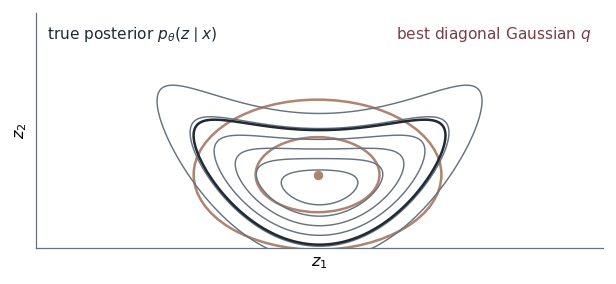

In [7]:
variational_gap()

### `make_vae_figures.py`

base model: reconstruction 20.2 nats, per-coordinate KL [1.81 1.47]


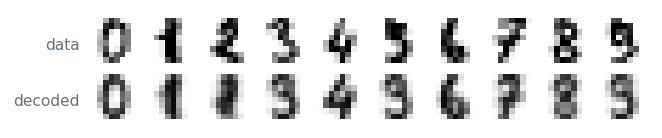

In [8]:
from __future__ import annotations


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn



SEED = 26520

digits = pd.read_csv(Path("SklearnDigits.csv"))
X = torch.tensor(digits.drop(columns="target").to_numpy(float) / 16.0, dtype=torch.float32)
Y = digits["target"].to_numpy(int)
N, D = X.shape


class VAE(nn.Module):
    def __init__(self, latent: int = 2, hidden: int = 128):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(D, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
        self.mean = nn.Linear(hidden, latent)
        self.log_variance = nn.Linear(hidden, latent)
        self.decoder = nn.Sequential(nn.Linear(latent, hidden), nn.ReLU(),
                                     nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, D))

    def encode(self, x):
        hidden = self.encoder(x)
        return self.mean(hidden), self.log_variance(hidden)

    def forward(self, x):
        mean, log_variance = self.encode(x)
        noise = torch.randn_like(mean)
        code = mean + torch.exp(.5 * log_variance) * noise
        return self.decoder(code), mean, log_variance


def train(beta: float = 1.0, latent: int = 2, epochs: int = 400, seed: int = SEED):
    """Full training run; returns the fitted model and the two loss components."""
    torch.manual_seed(seed)
    model = VAE(latent=latent)
    optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
    generator = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        order = torch.randperm(N, generator=generator)
        for start in range(0, N, 128):
            batch = X[order[start:start + 128]]
            logits, mean, log_variance = model(batch)
            reconstruction = nn.functional.binary_cross_entropy_with_logits(
                logits, batch, reduction="sum") / len(batch)
            divergence = -.5 * torch.sum(1 + log_variance - mean ** 2 - log_variance.exp()) / len(batch)
            optimizer.zero_grad()
            (reconstruction + beta * divergence).backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        logits, mean, log_variance = model(X)
        reconstruction = nn.functional.binary_cross_entropy_with_logits(
            logits, X, reduction="sum").item() / N
        per_coordinate = -.5 * torch.sum(1 + log_variance - mean ** 2 - log_variance.exp(), dim=0) / N
    return model, reconstruction, per_coordinate.numpy()


def show(ax, vector):
    ax.imshow(np.asarray(vector).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1, aspect="equal")
    ax.set_xticks([]); ax.set_yticks([])


def tile(images, columns):
    """Lay images out on one canvas, so every pixel stays square."""
    tiles = [np.pad(np.asarray(image).reshape(8, 8), 1, constant_values=0.0) for image in images]
    rows = int(np.ceil(len(tiles) / columns))
    while len(tiles) < rows * columns:
        tiles.append(np.zeros((10, 10)))
    return np.vstack([np.hstack(tiles[row * columns:(row + 1) * columns]) for row in range(rows)])


def reconstructions(model) -> None:
    index = [int(np.where(Y == digit)[0][0]) for digit in range(10)]
    with torch.no_grad():
        logits, _, _ = model(X[index])
        rebuilt = torch.sigmoid(logits).numpy()
    canvas = tile(list(X[index].numpy()) + list(rebuilt), columns=10)
    fig, ax = plt.subplots(figsize=(FULL_SHORT[0], FULL_SHORT[0] * canvas.shape[0] / canvas.shape[1]))
    ax.imshow(canvas, cmap="gray_r", vmin=0, vmax=1)
    ax.set(xticks=[], yticks=[5, 15], yticklabels=["data", "decoded"])
    ax.tick_params(length=0, labelsize=8.5)
    for spine in ax.spines.values():
        spine.set_visible(False)
    save(fig, OUT / "vae-reconstructions.pdf", OUT / "vae-reconstructions.svg")


def code_space(model) -> None:
    with torch.no_grad():
        mean, _ = model.encode(X)
    mean = mean.numpy()
    fig, ax = plt.subplots(figsize=FULL_TALL)
    scatter = ax.scatter(mean[:, 0], mean[:, 1], c=Y, cmap="tab10", s=7, alpha=.75)
    circle = plt.Circle((0, 0), 2, fill=False, color=INK, lw=1.0, ls="--")
    ax.add_patch(circle)
    ax.annotate("two standard deviations of $p(z)$", (.02, .04), xycoords="axes fraction",
                color=INK, fontsize=8)
    bar = fig.colorbar(scatter, ax=ax, fraction=.045, pad=.02, ticks=range(10))
    bar.set_label("digit (never shown to the model)")
    ax.set(xlabel="$z_1$", ylabel="$z_2$", xlim=(-4.2, 4.2), ylim=(-3.6, 3.6))
    ax.set_aspect("equal")
    save(fig, OUT / "vae-code-space.pdf", OUT / "vae-code-space.svg")


def prior_samples(model) -> None:
    torch.manual_seed(SEED + 5)
    with torch.no_grad():
        drawn = torch.sigmoid(model.decoder(torch.randn(30, 2))).numpy()
    canvas = tile(list(drawn), columns=10)
    fig, ax = plt.subplots(figsize=(FULL_SHORT[0], FULL_SHORT[0] * canvas.shape[0] / canvas.shape[1]))
    ax.imshow(canvas, cmap="gray_r", vmin=0, vmax=1)
    ax.set(xticks=[], yticks=[])
    for spine in ax.spines.values():
        spine.set_visible(False)
    save(fig, OUT / "vae-prior-samples.pdf", OUT / "vae-prior-samples.svg")


def beta_sweep() -> None:
    """Reconstruction quality and code usage as the KL weight changes."""
    settings = [.2, 1.0, 6.0]
    index = [int(np.where(Y == digit)[0][0]) for digit in (3, 6, 8)]
    summary = []
    for beta in settings:
        model, reconstruction, per_coordinate = train(beta=beta, epochs=250, seed=SEED + 11)
        with torch.no_grad():
            logits, _, _ = model(X[index])
            drawn = torch.sigmoid(logits).numpy()
        summary.append((beta, reconstruction, per_coordinate, drawn))
        print(f"beta {beta}: reconstruction {reconstruction:.1f} nats, "
              f"per-coordinate KL {np.round(per_coordinate, 2)}")

    fig, axes = plt.subplots(len(settings), 2, figsize=(FULL[0], 2.05),
                             gridspec_kw={"width_ratios": [1, 2.1]})
    for row, (beta, reconstruction, per_coordinate, drawn) in enumerate(summary):
        picture = axes[row, 0]
        picture.imshow(tile(list(drawn), columns=3), cmap="gray_r", vmin=0, vmax=1)
        picture.set(xticks=[], yticks=[])
        picture.set_ylabel(f"$\\beta={beta:g}$", fontsize=9)
        for spine in picture.spines.values():
            spine.set_visible(False)
        panel = axes[row, 1]
        panel.barh([1, 0], per_coordinate, color=[BLUE, MUTED], height=.55)
        panel.set(yticks=[1, 0], yticklabels=["$z_1$", "$z_2$"], xlim=(0, 3.2))
        panel.set_title(f"reconstruction {reconstruction:.0f} nats", fontsize=8.5, color=RED, pad=2)
        panel.tick_params(labelsize=8)
        if row == len(settings) - 1:
            panel.set_xlabel("KL per code coordinate (nats)", fontsize=8.5)
    fig.tight_layout(h_pad=.5, w_pad=.6)
    save(fig, OUT / "vae-beta-sweep.pdf", OUT / "vae-beta-sweep.svg")




# Calls preserved from the script's __main__ block.
fitted, error, coordinates = train()
print(f"base model: reconstruction {error:.1f} nats, per-coordinate KL {np.round(coordinates, 2)}")
reconstructions(fitted)

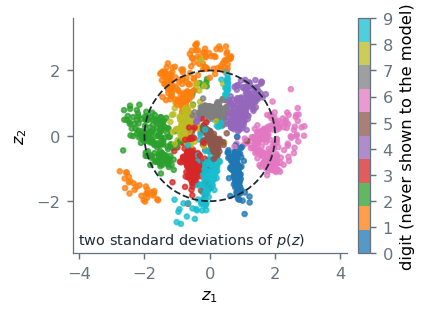

In [9]:
code_space(fitted)

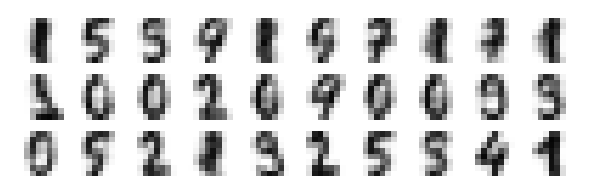

In [10]:
prior_samples(fitted)

beta 0.2: reconstruction 18.8 nats, per-coordinate KL [2.75 2.7 ]


beta 1.0: reconstruction 20.8 nats, per-coordinate KL [1.57 1.49]


beta 6.0: reconstruction 27.1 nats, per-coordinate KL [0. 0.]


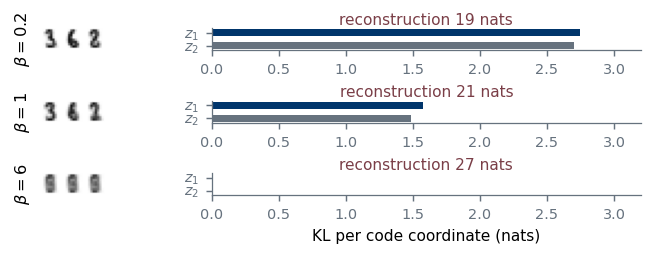

In [11]:
beta_sweep()